In [1]:
# Colab: install the only non-standard dependency (Arb ball arithmetic).
# The paper's computations used python-flint 0.9.0.
%pip install -q python-flint==0.9.0


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3.13 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Positivity of the radial intersection form: a window certificate and the prime sum behind it

Companion notebook to *The sign of the radial intersection form on the idele class group*
(`sign-radial-intersection-form-idele-class-group.pdf`, same folder).

* **Part 1 — The certificate on bounded windows** (rigorous). Re-runs, in Arb ball arithmetic, the
  finite-window lower-bound certificate of the section *Lower bounds on finite windows* (`sec:log5`), reproduces
  the paper's Theorem `thm:log5W` at $T=\tfrac12\log5$ exactly, and attempts the same certificate at a window
  $T$ of your choice.
* **Part 2 — The prime sum behind global positivity** (illustration, computed from the primes). Shows the
  quantity $G(x)$ that the step due to L. Alpoge bounds, on windows one can compute.
* **Part 3 — Putting the two together.** What was checked by computation, and what only a proof gives.

**Scope.** Part 1 certifies $W_T(F)\ge\mu\,\|F\|_2^2$ (and $\mathfrak a_T(F)\ge\mu\|F\|^2$ on the primitive
space) for **all** $F$ supported in $(-T,T)$, only for the windows you run. Section 8 reproduces the numerical part
of the separate statement (`eq:power-window`) that $W_T\ge e^{-120110026807}$ for $T\le 2.8022$, which comes from a different,
zero-side certificate and is conditional on three published facts about zeros in a bounded range (§8). Nothing in this notebook verifies
$W_T\ge0$ for every $T$; that is a theorem of the paper (Part 3).

---
# Part 1. The certificate on bounded windows


## 1. The form $W_T$

All of this is §2 of the paper. For $F\in L^2(-T,T)$ (extended by zero) put
$\widehat F(\tau)=\int F(t)e^{i\tau t}\,dt$ and

$$
m(\tau)=\operatorname{Re}\psi\!\big(\tfrac14+\tfrac{i\tau}{2}\big)-\log\pi ,\qquad
s_T(\tau)=m(\tau)-\sum_{n\in\mathcal N_T} v_n\cos(\tau\log n),\qquad v_n=\frac{2\Lambda(n)}{\sqrt n},
$$

where $\psi$ is the digamma function, $\Lambda$ the von Mangoldt function, and
$\mathcal N_T=\{n\ge2:\log n<2T\}$ the (finitely many) *contacts*; $A_T=\sum_{n\in\mathcal N_T}v_n$.
The truncated Weil form and the complete form are

$$
\mathfrak a_T(F)=\frac1{2\pi}\int_{\mathbb R}s_T(\tau)\,|\widehat F(\tau)|^2\,d\tau ,\qquad
W_T(F)=\mathfrak a_T(F)+2\operatorname{Re}\big(A(F)\overline{B(F)}\big),
$$

with the Tate moments $A(F)=\int F(t)e^{t/2}dt$, $B(F)=\int F(t)e^{-t/2}dt$. The primitive space is
$\mathcal P_T=\{A=B=0\}$, and

$$
\lambda_{\rm A}(T)=\inf_{F\in\mathcal P_T,\ \|F\|=1}\mathfrak a_T(F),\qquad
\lambda^{\rm W}_T=\inf_{\|F\|=1}W_T(F)\ \le\ \lambda_{\rm A}(T).
$$

By the explicit formula, for smooth real $F$, $W_T(F)=\sum_\rho\Phi_F(\rho)\Phi_F(1-\rho)$ over the
nontrivial zeros of $\zeta$ ($\Phi_F(s)=\int F(t)e^{(s-1/2)t}dt$). The paper shows that
$W_T\ge0$ on every window is equivalent to the Riemann hypothesis (Theorem `thm:all-support`).

**Status of positivity for every $T$.** In the paper, $W_T\ge0$ for *every* $T>0$ is a theorem
*given* the theorem on families of column packages of L. Alpoge (Theorem `thm:alpoge-families`, which
rests on his Lean formalisation and is not yet written out in full on paper). This notebook does not
touch that argument. It is an **independent, finite, unconditional check on specific windows**: it uses
only the archimedean side (digamma values) and the finitely many prime contacts; it uses no zeros of
$\zeta$ and no RH-type input. A PASS here is evidence about one window, not a proof of anything for all
$T$.

**Monotonicity.** If $F$ is supported in $(-T',T')$ with $T'<T$, then $\mathfrak a_{T}(F)=\mathfrak a_{T'}(F)$
and $W_T(F)=W_{T'}(F)$ (Lemma `lem:monoT`). Hence a certificate at $T$ holds for every $0<T'\le T$.


## 2. What is certified, and by which finite computation

Everything below is Proposition `prop:lowercert` and the paragraph *The computation* of the paper.
Work in one parity sector (even or odd functions); the form splits over parities (Theorem
`thm:parityschur`(o)): on even $F$, $A=B=\ell_{\rm ev}(F)=\langle F,\cosh\frac t2\rangle$, so
$W_T=\mathfrak a_T+2\ell_{\rm ev}^2$; on odd $F$, $A=-B=\ell_{\rm odd}(F)=\langle F,\sinh\frac t2\rangle$,
so $W_T=\mathfrak a_T-2\ell_{\rm odd}^2$; and $\mathcal P_T$ is $\ker\ell$ in each sector.

1. **Lower symbol.** Choose a frequency cut $\tau_N$ and $s_\infty\le m(\tau_N)-A_T$. Because $m$ is
   increasing and the prime comb is $\ge -A_T$, the function equal to $s_T$ on $|\tau|\le\tau_N$ and to
   $s_\infty$ beyond is $\le s_T$. So
   $\mathfrak a_T(F)\ge s_\infty\|F\|^2-\langle\mathcal G F,F\rangle$ with $\mathcal G=Q_Tg(D)Q_T$,
   $g=(s_\infty-s_T)\mathbf 1_{|\tau|<\tau_N}$, and $0\le\mathcal G_\pm\le\omega_\pm S_{c_*}$, where
   $S_c$ is the time–band limiting operator, $c_*=T\tau_N$,
   $\omega_+=s_\infty-m(0)+A_T$, $\omega_-=m(\tau_N)+A_T-s_\infty$.
2. **Legendre basis.** $e_j(t)=\sqrt{(2j+1)/2T}\,P_j(t/T)$. Split $L^2_{\rm par}=E\oplus Y$ with
   $E=\mathrm{span}\{e_j:j<k_1\}$. The Ky Fan bound (Lemma `lem:KyFan`, Corollary `cor:P1`) gives
   $\|P_Y\mathcal G_+P_Y\|\le\omega_+\Lambda_{k_1}(c_*)\le\omega_+\Lambda^*_{k_1}(c_*)$, with
   $\Lambda^*_k(c)=\frac2\pi\sum_{j\ge k}c^{2j+1}/((2j+1)!!)^2$, so on $Y$ the form is
   $\ge q_Y=s_\infty-\mu-\omega_+\Lambda^*_{k_1}(c_*)$.
3. **Gram entries.** $\langle\mathcal Ge_i,e_l\rangle=\frac{2T}{\pi}\sqrt{(2i+1)(2l+1)}(-1)^{(l-i)/2}
   \int_0^{\tau_N}g(\tau)j_i(\tau T)j_l(\tau T)\,d\tau$ ($j_n$ spherical Bessel), for $i,l<k_2$,
   computed by composite Gauss–Legendre quadrature with **rigorous** nodes/weights and the Bernstein
   ellipse remainder bound (Trefethen, *ATAP*, Thm 19.3) added as a ball to every entry.
   Couplings to $l\ge k_2$ are bounded by $(\omega_++\omega_-)\Lambda^*_{k_2}(c_*)^{1/2}$ (Cauchy–Schwarz).
4. **Bordered Schur complement.** Eliminating $Y$ gives an explicit symmetric matrix $\mathsf R$ of size
   $k_1/2+1$ on $E\oplus\mathbb R$ (the extra row/column carries the Tate functional, with
   $\langle e_l,\chi\rangle=\sqrt{(2l+1)/2T}\,2T\,i_l(T/2)$), such that the number of negative squares of
   the bordered form is at most $n_-(\mathsf R)$.
5. **Inertia test (ball arithmetic).** With $c=0$ (primitive form) or $c=\mp\frac12$ (complete form, even/odd):
   * $n_-(\mathsf R)\le1$, $c=0$ $\Rightarrow$ $\mathfrak a_T\ge\mu$ on the unit sphere of $\mathcal P_T^{\rm par}$;
   * $n_-(\mathsf R)\le1$, $c=-\frac12$, even $\Rightarrow$ $W_T\ge\mu\|\cdot\|^2$ on even $F$;
   * $n_-(\mathsf R)=0$, $c=+\frac12$, odd $\Rightarrow$ $W_T\ge\mu\|\cdot\|^2$ on odd $F$.

   $n_-=0$ is proved by a ball $LDL^{\mathsf T}$ factorisation with every pivot certified $>0$ (blocked; if the
   ball radii grow too much, as happens for $\dim\gtrsim300$, by an exact congruence $X\mathsf RX^{\mathsf T}$ with
   $X$ an exactly representable unit lower-triangular approximate inverse factor, followed by a ball Gershgorin
   test — Rump's method);
   $n_-\le1$ by a pivot block with certified negative determinant (the $\xi\xi$ entry, or a $2\times2$
   block on $(e_0,\xi)$) whose Schur complement is certified positive definite (Haynsworth inertia
   additivity). The paper uses a Householder congruence for the same purpose; any congruence is valid.

**Every number is a ball** (midpoint ± radius, Arb). A case prints **PASS** only if every inequality
above is a proved ball predicate. If any ball is too wide, or any hypothesis fails, the case prints
FAIL / *no certificate produced by this method*, never PASS.

**Implementation notes (deviations from the paper, none affecting rigor).**
(i) Default working precision 256 bits (paper: 640); Bessel values are computed at an automatically raised
precision ($\approx$ prec $+1.5\,\tau T$ bits), because the Bessel recurrence and series lose that much.
(ii) Two quadrature rules: `quad="paper"` is the paper's (46 nodes on panels of length 1/2, $\rho=3.2$,
22 080 nodes at $T_5$); `quad="wide"` (default) keeps those panels on $[0,2]$ and uses panels of length 4
with 56 nodes and $\rho=2.4$ beyond, whose ellipses stay in $\operatorname{Re}z>0$, away from the poles of
$\psi(\frac14\pm\frac{iz}2)$ (all on the imaginary axis). The ellipse bound $M$ is computed per panel by
evaluating $|g(z)|e^{2T|\operatorname{Im}z|}$ on Arb boxes covering the ellipse (maximum modulus), with
$|j_n(w)|\le e^{|\operatorname{Im}w|}$, and the digamma enclosed by $\psi(w)=\psi(w+8)-\sum_{k<8}(w+k)^{-1}$,
$\psi(u)=\log u-\frac1{2u}-E$, $|E|\le\frac1{2\operatorname{Re}u}$ (DLMF 5.9.13).
(iii) The remainder exponent uses the weaker point-count convention, $\rho^{-2n+2}$ for $n$ nodes.


## 3. Parameters

In [2]:
# ---- user parameters -------------------------------------------------------
# Window: 'halflog:N' means T = (1/2) log N exactly; otherwise a decimal or fraction, e.g. '0.9', '9/10'.
T_SPEC    = "0.85"     # beyond T_5 = 0.8047; ~5 min locally (dim 595 per parity); "halflog:5": seconds
PREC_BITS = 256        # Arb working precision (paper: 640). Bessel values get extra bits automatically.
QUAD      = "wide"     # "wide" (fast) or "paper" (the paper's exact rule; ~15x more nodes)
# Truncation parameters: None = automatic (tau_N from S_TARGET, k1/k2 from LAMBDA targets).
TAU_N, K1, K2 = None, None, None
S_TARGET  = 0.7        # s_inf = m(tau_N) - A_T aimed at (paper: 0.7008 at T_5)
LAMBDA_K1 = 1e-20      # Lambda*_{k1}(c*) target (paper: 4.41e-20)
LAMBDA_K2 = 1e-70      # Lambda*_{k2}(c*) target (paper: 3.9e-70)
MAX_DIM   = 700        # refuse (and say so) if the Legendre block per parity is larger than this
MU_LIST   = ("1e-2", "1e-4", "1e-6", "1e-8", "1e-10", "1e-12", "1e-14", "1e-16", "1e-18",
             "1e-20", "1e-24", "1e-28", "1e-32", "1e-40", "0")   # tried in this order

## 4. The certificate code
Self-contained; only `python-flint` (Arb) and the standard library. Read it: the PASS logic is in
`certify_inertia` and `run_window`.

In [3]:
# Rigorous lower certificate of Section "Lower bounds on finite windows"
# (Proposition lowercert), parameterised in T.  Ball arithmetic: python-flint (Arb).
import math, time
from fractions import Fraction
from flint import arb, acb, arb_mat, ctx


# ---------------------------------------------------------------- the window
class Window:
    """T is either exactly (1/2) log N  (spec 'halflog:N') or a rational."""
    def __init__(self, spec):
        spec = str(spec).strip()
        if spec.startswith("halflog:"):
            self.kind, self.N = "halflog", int(spec.split(":")[1])
            self.label = "T = (1/2) log %d" % self.N
            self.approx = 0.5 * math.log(self.N)
        else:
            self.kind, self.q = "rational", Fraction(spec)
            self.label = "T = %s" % spec
            self.approx = float(self.q)
        if self.approx <= 0:
            raise ValueError("T must be positive")

    def T(self):
        if self.kind == "halflog":
            return arb(self.N).log() / 2
        return arb(self.q.numerator) / self.q.denominator

    def is_contact(self, n):
        """n is a contact iff log n < 2T (strict), decided exactly."""
        if self.kind == "halflog":
            return n < self.N
        lhs, rhs = arb(n).log(), 2 * self.T()
        if lhs < rhs:
            return True
        if lhs >= rhs:
            return False
        raise ArithmeticError("cannot decide log %d < 2T at this precision" % n)


def mangoldt_p(n):
    """returns p if n = p^k (k>=1), else None."""
    for p in range(2, int(n ** 0.5) + 2):
        if n % p == 0:
            while n % p == 0:
                n //= p
            return p if n == 1 else None
    return n if n >= 2 else None


def contacts(win):
    out, n = [], 2
    while win.is_contact(n):
        p = mangoldt_p(n)
        if p is not None:
            out.append((n, p))
        n += 1
    return out


def m_real(tau):
    """m(tau) = Re psi(1/4 + i tau/2) - log pi, tau real (arb)."""
    return acb(arb(1) / 4, tau / 2).digamma().real - arb.pi().log()


def m_complex(z):
    """analytic continuation: (psi(1/4+iz/2)+psi(1/4-iz/2))/2 - log pi."""
    w = acb(0, 1) * z / 2
    q = acb(arb(1) / 4)
    return (psi_shift(q + w) + psi_shift(q - w)) / 2 - arb.pi().log()


def psi_shift(w, N=8):
    """enclosure of psi(w) valid on a whole box w (Arb's digamma is too coarse
    on wide boxes).  psi(w) = psi(w+N) - sum_{k<N} 1/(w+k), and for Re u > 0
    psi(u) = log u - 1/(2u) - E(u) with |E(u)| <= 1/(2 Re u)
    (DLMF 5.9.13: E(u) = int_0^oo g(t) e^{-ut} dt, 0 <= g <= 1/2)."""
    u = w + N
    reu = u.real.lower()
    if not reu > 0:
        raise ArithmeticError("psi_shift: Re(w+N) not positive")
    s = u.log() - 1 / (2 * u)
    for k in range(N):
        s -= 1 / (w + k)
    e = (1 / (2 * arb(reu))).upper()
    return acb(arb(s.real.mid(), s.real.rad() + e), arb(s.imag.mid(), s.imag.rad() + e))


def lam_star(k, c):
    """Upper bound for Lambda*_k(c) = (2/pi) sum_{j>=k} c^{2j+1}/((2j+1)!!)^2
    (Corollary P1).  Terms are summed exactly until the ratio
    c^2/(2j+3)^2 <= 1/4, then the remainder is bounded geometrically."""
    c = arb(c)
    def log_dfact(m):   # log((2m+1)!!) = lgamma(2m+2) - m log 2 - lgamma(m+1)
        return arb(2 * m + 2).lgamma() - m * arb(2).log() - arb(m + 1).lgamma()
    j = k
    term = ((2 * j + 1) * c.log() - 2 * log_dfact(j)).exp()
    total = arb(0)
    while True:
        r = c * c / ((2 * j + 3) ** 2)
        if r.upper() <= 0.25:
            total += term / (1 - r)   # ratios are decreasing in j
            break
        total += term
        term *= r
        j += 1
    return (2 / arb.pi()) * total


# ------------------------------------------------------- spherical Bessel
def sph_j_all(x, L):
    """[j_0(x),...,j_{L-1}(x)] for real x>0 by downward recurrence started
    from two Arb Bessel values (ball arithmetic throughout)."""
    # the hypergeometric series behind J_nu(x) cancels like e^x: give Arb
    # enough working precision for the two starting values
    xm = arb(x.mid())     # exact; the recurrence is run at the midpoint (the
                          # ball radius of x would otherwise excite the dominant solution)
    # Extra working precision: (i) the hypergeometric series behind J_nu(x)
    # cancels like e^x; (ii) in the oscillatory range l < x ball radii of the
    # three-term recurrence grow geometrically (wrapping), by < 2^(1.5 x) overall.
    prec0 = ctx.prec
    wp = prec0 + int(1.5 * float(x.upper())) + 64
    while True:   # Arb returns a correct but possibly wide ball: retry until sharp
        with ctx.workprec(wp):
            pref = (arb.pi() / (2 * xm)).sqrt()
            jL = xm.bessel_j(arb(2 * L + 1) / 2) * pref
            jL1 = xm.bessel_j(arb(2 * L - 1) / 2) * pref
        if all(v.rel_accuracy_bits() > prec0 + 20 for v in (jL, jL1)) or wp > 64 * prec0 + 20000:
            break
        wp *= 2
    with ctx.workprec(wp):
        out = [None] * L
        out[L - 1] = jL1
        nxt, cur = jL, jL1
        for l in range(L - 1, 0, -1):
            prev = (2 * l + 1) * cur / xm - nxt
            out[l - 1] = prev
            nxt, cur = cur, prev
    out = [+v for v in out]     # round to the working precision (radius absorbs it)
    # back from the exact midpoint xm to the ball x:  |j_l'| <= 1/2 on R
    r = x.rad() / 2
    return [arb(v.mid(), v.rad() + r) for v in out]


def sph_i(l, x):
    """modified spherical Bessel i_l(x) = sqrt(pi/(2x)) I_{l+1/2}(x)."""
    return (arb.pi() / (2 * x)).sqrt() * x.bessel_i(arb(l) + arb(1) / 2)


# ------------------------------------------------------------- quadrature
def panels_paper(tauN, h=Fraction(1, 2), n=46, rho=Fraction(16, 5)):
    """the paper's rule: composite Gauss-Legendre, n nodes on panels of length h."""
    P, a = [], Fraction(0)
    while a < tauN:
        P.append((a, h, n, rho))
        a += h
    if a != tauN:
        raise ValueError("tau_N must be a multiple of the panel length")
    return P


def panels_wide(tauN, n_near=46, h_far=4, n_far=56, rho_far=Fraction(12, 5), near=2):
    """same theorem, fewer nodes: the paper's panels on [0,near], then wide
    panels (their Bernstein ellipses stay in Re z > 0, away from the poles
    of psi(1/4 +- iz/2), which all lie on the imaginary axis)."""
    P = panels_paper(Fraction(near), n=n_near)
    a = Fraction(near)
    while a < tauN:
        h = min(Fraction(h_far), Fraction(tauN) - a)
        P.append((a, h, n_far, rho_far))
        a += h
    return P


def ellipse_ok(a, h, rho):
    """poles of the integrand: z = +-i(2k+1/2).  Sufficient: the ellipse lies
    in |Im z| < 1/2, or in Re z > 0."""
    a, h, rho = Fraction(a), Fraction(h), Fraction(rho)
    semi_minor = (h / 2) * (rho - 1 / rho) / 2
    semi_major = (h / 2) * (rho + 1 / rho) / 2
    return semi_minor < Fraction(1, 2) or a + h / 2 - semi_major > 0


def panel_M(a, h, rho, T, sinf, vlogs, K=96):
    """rigorous upper bound of |g(z) j_i(zT) j_l(zT)| on the Bernstein ellipse
    (max modulus on boundary boxes), using |j_n(w)| <= exp|Im w|."""
    a, h, rho = arb(a.numerator) / a.denominator, arb(h.numerator) / h.denominator, \
        arb(rho.numerator) / rho.denominator
    c0 = a + h / 2
    A = (h / 2) * (rho + 1 / rho) / 2
    B = (h / 2) * (rho - 1 / rho) / 2
    r = A * arb.pi() / K * arb("1.0001")
    best = 0.0
    for k in range(K):
        th = 2 * arb.pi() * k / K
        x = c0 + A * th.cos()
        y = B * th.sin()
        z = acb(arb(x.mid(), x.rad() + r.upper()), arb(y.mid(), y.rad() + r.upper()))
        gz = sinf - m_complex(z)
        for (v, lg) in vlogs:
            gz += v * (z * lg).cos()
        bound = abs(gz) * (2 * T * abs(z.imag)).exp()
        u = float(bound.upper()) * (1 + 1e-12)
        if not math.isfinite(u):
            return float("inf")
        best = max(best, u)
    return best


# ---------------------------------------------------- the whole certificate
class Certificate:
    def __init__(self, Tspec, tauN, k1, k2, prec=320, quad="paper", verbose=True):
        self.log = []
        self.say = (lambda *s: print(*s, flush=True)) if verbose else (lambda *s: None)
        ctx.prec = prec
        self.prec = prec
        self.win = Window(Tspec)
        self.tauN = Fraction(tauN)
        self.k1, self.k2 = k1, k2
        if k1 % 2 or k2 % 2 or not (0 < k1 < k2):
            raise ValueError("need even 0 < k1 < k2")
        self.quad = quad
        self.ok_setup = False
        self.fail_reason = None
        self._setup()

    # ---- scalar data
    def _setup(self):
        t0 = time.time()
        W = self.win
        T = W.T()
        self.T = T
        C = contacts(W)
        self.contacts = C
        self.vlogs = [((2 * arb(p).log()) / arb(n).sqrt(), arb(n).log()) for n, p in C]
        Aconst = sum((v for v, _ in self.vlogs), arb(0))
        self.Aconst = Aconst
        tauN = arb(self.tauN.numerator) / self.tauN.denominator
        mN = m_real(tauN)
        C0 = arb(1) / 4
        C0 = acb(C0).digamma().real - arb.pi().log()
        # s_inf <= m(tau_N) - A : take an exact dyadic just below the lower endpoint
        sinf = arb((mN - Aconst).lower())
        self.mN, self.C0, self.sinf = mN, C0, sinf
        self.omega_p = arb((sinf - C0 + Aconst).upper())
        self.omega_m = arb((mN + Aconst - sinf).upper())
        self.cstar = T * tauN
        self.L1 = arb(lam_star(self.k1, self.cstar).upper())
        self.L2 = arb(lam_star(self.k2, self.cstar).upper())
        self.say("window      :", W.label, " (T = %s)" % T.str(12, radius=False))
        self.say("contacts    :", [n for n, _ in C], "  A_T =", Aconst.str(10))
        self.say("tau_N       :", float(self.tauN), "  m(tau_N) =", mN.str(10),
                 "  C_0 = m(0) =", C0.str(10))
        self.say("s_inf       :", sinf.str(12), "(must be > 0)")
        self.say("omega_+/-   :", self.omega_p.str(6), self.omega_m.str(6))
        self.say("c* = T tau_N:", self.cstar.str(8), "  k1 =", self.k1, " k2 =", self.k2,
                 " (dim E = %d per parity)" % (self.k1 // 2))
        self.say("Lambda*_k1  : %.3e   Lambda*_k2 : %.3e" % (float(self.L1.upper()), float(self.L2.upper())))
        if not (sinf > 0):
            self.fail_reason = ("s_inf = m(tau_N) - A_T is not positive: tau_N is too small for the "
                                "prime mass A_T of this window (need m(tau_N) > A_T).")
            self.say("FAIL(setup):", self.fail_reason)
            return
        self._matrices()
        self.ok_setup = True
        self.say("setup time  : %.1f s" % (time.time() - t0))

    # ---- the Gram matrices <G e_i, e_l> by quadrature + remainder ball
    def _matrices(self):
        T, k2 = self.T, self.k2
        P = panels_paper(self.tauN) if self.quad == "paper" else panels_wide(self.tauN)
        t0 = time.time()
        # rigorous remainder
        err = arb(0)
        Mcache = {}
        for (a, h, n, rho) in P:
            if not ellipse_ok(a, h, rho):
                raise ValueError("Bernstein ellipse of panel at %s meets a pole" % a)
            M = panel_M(a, h, rho, T, self.sinf, self.vlogs)
            rho_a = arb(rho.numerator) / rho.denominator
            e = (arb(h.numerator) / h.denominator / 2) * arb(64) / 15 * arb(M) \
                * rho_a ** (-(2 * n - 2)) / (rho_a ** 2 - 1)
            err += e
        self.quad_err_integral = arb(err.upper())
        # entry error: (2T/pi) sqrt((2i+1)(2l+1)) <= (2T/pi)(2 k2)
        self.entry_err = arb(((2 * T / arb.pi()) * (2 * k2) * err).upper())
        self.say("quadrature  : %d panels, %d nodes; remainder per entry <= %.2e  (%.1f s)" %
                 (len(P), sum(p[2] for p in P), float(self.entry_err.upper()), time.time() - t0))
        # nodes, accumulated in chunks (memory)
        t0 = time.time()
        rules = {}
        nodes = []
        for (a, h, n, rho) in P:
            if n not in rules:
                rules[n] = [arb.legendre_p_root(n, k, weight=True) for k in range(n)]
            aa, hh = arb(a.numerator) / a.denominator, arb(h.numerator) / h.denominator
            for (x, w) in rules[n]:
                nodes.append((aa + hh * (1 + x) / 2, w * hh / 2))
        nI = k2 // 2
        raw = {0: arb_mat(nI, nI), 1: arb_mat(nI, nI)}
        maxrad = 0.0
        CH = 512
        for c0 in range(0, len(nodes), CH):
            rows, wg = {0: [], 1: []}, []
            for (tau, ww) in nodes[c0:c0 + CH]:
                g = self.sinf - m_real(tau)
                for (v, lg) in self.vlogs:
                    g += v * (tau * lg).cos()
                js = sph_j_all(tau * T, k2)
                maxrad = max(maxrad, max(float(j.rad()) for j in js))
                wg.append(ww * g)
                rows[0].append(js[0::2])
                rows[1].append(js[1::2])
            for p in (0, 1):
                J = arb_mat(rows[p])
                DJ = arb_mat([[wg[r] * e for e in rows[p][r]] for r in range(len(wg))])
                raw[p] = raw[p] + J.transpose() * DJ
        self.max_bessel_rad = maxrad
        self.n_nodes = len(nodes)
        self.say("Gram data   : %d nodes x %d Bessel orders, max Bessel ball radius %.2e  (%.1f s)" %
                 (len(nodes), k2, maxrad, time.time() - t0))
        t0 = time.time()
        self.G, self.chi, self.chinorm2 = {}, {}, {}
        two_T_over_pi = 2 * T / arb.pi()
        eerr = self.entry_err.upper()
        for p in (0, 1):
            idx = list(range(p, k2, 2))
            s = [(-1) ** (l // 2) * arb(2 * l + 1).sqrt() for l in idx]
            G = [[None] * nI for _ in range(nI)]
            for a_ in range(nI):
                for b_ in range(a_, nI):
                    val = two_T_over_pi * s[a_] * s[b_] * raw[p][a_, b_]
                    val = arb(val.mid(), val.rad() + eerr)
                    G[a_][b_] = G[b_][a_] = val
            self.G[p] = G
            # Tate border: <e_l, chi_par> = sqrt((2l+1)/2T) 2T i_l(T/2)
            self.chi[p] = [((2 * l + 1) / (2 * T)).sqrt() * 2 * T * sph_i(l, T / 2) for l in idx]
            self.chinorm2[p] = (T.sinh() + T) if p == 0 else (T.sinh() - T)
        self.say("Gram blocks : 2 parities, %d x %d each  (%.1f s)" % (nI, nI, time.time() - t0))

    # ---- the bordered matrix R of Proposition lowercert(b)
    def R_matrix(self, par, c, mu):
        mu = arb(mu)
        n1 = self.k1 // 2
        G, x = self.G[par], self.chi[par]
        nI = len(G)
        Yr = range(n1, nI)
        qY = self.sinf - mu - self.omega_p * self.L1
        if not (qY > 0):
            return None, "q_Y = s_inf - mu - omega_+ Lambda*_k1 is not certified positive (%s)" % qY.str(5)
        q = arb(qY.lower())                         # exact, 0 < q <= q_Y
        tG = (self.omega_p + self.omega_m) * self.L2.sqrt()
        tail_chi2 = self.chinorm2[par] - sum((x[l] ** 2 for l in range(nI)), arb(0))
        ub = max(0.0, float(tail_chi2.upper())) * (1 + 1e-9) + 1e-300
        tchi = arb(ub).sqrt()
        PYchi2 = sum((x[l] ** 2 for l in Yr), arb(0)) + arb(ub / 2, ub / 2)
        R = [[None] * (n1 + 1) for _ in range(n1 + 1)]
        tG2 = (tG * tG).upper()
        GEY = arb_mat([[G[i][l] for l in Yr] for i in range(n1)])
        CPL = GEY * GEY.transpose()
        CX = GEY * arb_mat([[x[l]] for l in Yr])
        txc = (tG * tchi).upper()
        for i in range(n1):
            for j in range(i, n1):
                cpl = CPL[i, j]
                cpl = arb(cpl.mid(), cpl.rad() + tG2)
                v = -G[i][j] - cpl / q
                if i == j:
                    v += self.sinf - mu
                R[i][j] = R[j][i] = v
            cx = CX[i, 0]
            cx = arb(cx.mid(), cx.rad() + txc)
            R[i][n1] = R[n1][i] = x[i] + cx / q
        R[n1][n1] = arb(c) - PYchi2 / q
        info = dict(qY=qY, tG=tG, tchi=tchi)
        return R, info


# ----------------------------------------------------- inertia certificates
def ldl_pd(A):
    """ball LDL^T; returns (True, min pivot ball, n) if every pivot is certified > 0,
    else (False, offending pivot ball, its index)."""
    n = len(A)
    A = [row[:] for row in A]
    piv = []
    for k in range(n):
        d = A[k][k]
        if not (d > 0):
            return False, d, k
        piv.append(d)
        col = [A[j][k] for j in range(n)]          # lower triangle, column k
        for i in range(k + 1, n):
            f = col[i] / d
            Ai = A[i]
            for j in range(k + 1, i + 1):           # only the lower triangle is used
                Ai[j] = Ai[j] - f * col[j]
    mn = min(piv, key=lambda b: float(b.mid()))
    return True, mn, n


def pd_blocked(A, block=64):
    """certify A (list of lists of arb, symmetric) positive definite: ball LDL on a
    leading block, then the Schur complement of the rest (Arb matrix solve/product),
    recursively.  Inertia additivity: A > 0 iff block > 0 and Schur complement > 0."""
    n = len(A)
    if n <= 2 * block:
        return ldl_pd(A)
    ok, mn, k = ldl_pd([row[:block] for row in A[:block]])
    if not ok:
        return False, mn, k
    B = arb_mat([row[:block] for row in A[:block]])
    Cm = arb_mat([row[block:] for row in A[:block]])
    X = B.solve(Cm, nonstop=True)
    S = arb_mat([row[block:] for row in A[block:]]) - Cm.transpose() * X
    m = n - block
    Sl = [[S[i, j] for j in range(m)] for i in range(m)]
    for i in range(m):              # symmetrize: intersect not needed, take lower triangle
        for j in range(i + 1, m):
            Sl[i][j] = Sl[j][i]
    ok2, mn2, k2 = pd_blocked(Sl, block)
    if not ok2:
        return False, mn2, block + k2
    return True, (mn if float(mn.mid()) < float(mn2.mid()) else mn2), n

def pd_precond(A):
    """certify A > 0 by an exact congruence C = X A X^T with X = (approximate L)^{-1},
    X unit lower triangular with exact (midpoint) entries, hence invertible, followed by
    a Gershgorin test on C in ball arithmetic (Rump-style; radii grow only linearly)."""
    n = len(A)
    M = [[arb(A[i][j].mid()) for j in range(n)] for i in range(n)]
    L = [[arb(0)] * n for _ in range(n)]
    for k in range(n):                     # approximate LDL^T of the midpoint matrix
        d = M[k][k]
        L[k][k] = arb(1)
        if d == 0:
            return False, d, k
        for i in range(k + 1, n):
            f = arb((M[i][k] / d).mid())
            L[i][k] = f
            Mi = M[i]
            for j in range(k + 1, i + 1):
                Mi[j] = arb((Mi[j] - f * M[j][k]).mid())
    Lm = arb_mat(L)
    Xb = Lm.solve(arb_mat([[1 if i == j else 0 for j in range(n)] for i in range(n)]), nonstop=True)
    X = arb_mat([[arb(Xb[i, j].mid()) if j < i else (arb(1) if i == j else arb(0))
                  for j in range(n)] for i in range(n)])
    Afull = arb_mat([[A[max(i, j)][min(i, j)] for j in range(n)] for i in range(n)])
    Cm = X * Afull * X.transpose()
    piv = []
    for i in range(n):
        off = arb(0)
        for j in range(n):
            if j != i:
                off += abs(Cm[i, j])
        g = Cm[i, i] - off
        if not (g > 0):
            return False, g, i
        piv.append(Cm[i, i])
    return True, min(piv, key=lambda b: float(b.mid())), n


def pd_test(A):
    """A > 0 certified by ball LDL (blocked); if a pivot ball is merely too wide,
    retry with the preconditioned Gershgorin test."""
    ok, mn, k = pd_blocked(A)
    if ok or (mn is not None and mn < 0):
        return ok, mn, k
    return pd_precond(A)


def schur(R, piv_idx):
    """Schur complement of R w.r.t. the principal block on piv_idx."""
    n = len(R)
    rest = [i for i in range(n) if i not in piv_idx]
    if len(piv_idx) == 1:
        p = piv_idx[0]
        d = R[p][p]
        S = [[R[i][j] - R[i][p] * R[p][j] / d for j in rest] for i in rest]
        return S
    p, q = piv_idx
    a, b, c = R[p][p], R[p][q], R[q][q]
    det = a * c - b * b
    ia, ib, ic = c / det, -b / det, a / det   # inverse of [[a,b],[b,c]]
    S = []
    for i in rest:
        ui, wi = R[i][p], R[i][q]
        ti, si = ia * ui + ib * wi, ib * ui + ic * wi
        S.append([R[i][j] - ti * R[p][j] - si * R[q][j] for j in rest])
    return S


def certify_inertia(R, max_neg):
    """certify n_-(R) <= max_neg (0 or 1). Returns (ok, message, min pivot)."""
    n = len(R)
    if max_neg == 0:
        ok, mn, k = pd_test(R)
        if ok:
            return True, "n_-(R) = 0 (all %d LDL pivots certified > 0)" % n, mn
        return False, "LDL pivot %d not certified positive: %s" % (k, mn.str(5)), mn
    xi = n - 1
    tried = []
    if R[xi][xi] < 0:
        S = schur(R, [xi])
        ok, mn, k = pd_test(S)
        if ok:
            return True, ("R_xixi < 0 certified and its Schur complement is positive definite: "
                          "n_-(R) = 1 (Haynsworth)"), mn
        tried.append("xi-pivot: Schur pivot %d = %s" % (k, mn.str(5)))
    i0 = max(range(n - 1), key=lambda i: abs(float(R[i][xi].mid())))
    det = R[i0][i0] * R[xi][xi] - R[i0][xi] ** 2
    if det < 0:
        S = schur(R, [i0, xi])
        ok, mn, k = pd_test(S)
        if ok:
            return True, ("2x2 block on (e_%d, xi) has certified det < 0 and its Schur complement is "
                          "positive definite: n_-(R) = 1 (Haynsworth)" % i0), mn
        tried.append("2x2-pivot: Schur pivot %d = %s" % (k, mn.str(5)))
    else:
        tried.append("2x2 block det not certified negative")
    return False, "; ".join(tried), None


# ------------------------------------------------------ automatic parameters
def auto_params(Tspec, s_target=0.7, lam1=1e-20, lam2=1e-70, prec=256):
    """tau_N: smallest even integer with m(tau_N) - A_T >= s_target;
    k1, k2: smallest even k with Lambda*_k(T tau_N) <= lam1, lam2."""
    with ctx.workprec(prec):
        W = Window(Tspec)
        T = W.T()
        A = sum((2 * arb(p).log() / arb(n).sqrt() for n, p in contacts(W)), arb(0))
        tau = 2 * max(1, int(math.floor(math.pi * math.exp(float(A.mid()) + s_target))))
        while not (m_real(arb(tau)) - A >= s_target):
            tau += 2
        c = T * tau
        k = 2 * int(float(c.upper()) / 2)
        while not (lam_star(k, c) <= lam1):
            k += 2
        k1 = k
        while not (lam_star(k, c) <= lam2):
            k += 2
        return dict(tauN=tau, k1=k1, k2=k, A=float(A.mid()), cstar=float(c.mid()))


def fmt(b, d=6):
    return "%s (± %.1e)" % (b.mid().str(d, radius=False), float(b.rad()))


CASES = [  # name, parity (0 even, 1 odd), c, allowed negative squares
    ("primitive  a_T | P_T, even", 0, 0, 1),
    ("primitive  a_T | P_T, odd ", 1, 0, 1),
    ("complete   W_T,       even", 0, -1, 1),   # c = -1/2
    ("complete   W_T,       odd ", 1, 1, 0),    # c = +1/2
]


def certify_case(C, case, mu):
    name, par, c2, maxneg = case
    R, info = C.R_matrix(par, arb(c2) / 2, arb(mu))
    if R is None:
        return False, info, None
    ok, msg, mn = certify_inertia(R, maxneg)
    return ok, msg, mn


# ------------------------------------------------------------------ driver
def run_window(Tspec, tauN=None, k1=None, k2=None, prec=256, quad="wide",
               mus=("1e-8", "1e-10", "1e-12", "1e-14", "1e-16", "1e-18", "1e-20",
                    "1e-24", "1e-28", "1e-32", "0"),
               s_target=0.7, lam1=1e-20, lam2=1e-70, max_dim=400, verbose=True):
    """Attempt the certificate of Proposition lowercert at the window Tspec.
    For each of the four cases, tries mu in the given (decreasing) order and
    stops at the first mu that is certified.  Returns a dict of results.
    PASS is printed only when every inequality of the certificate is a
    proved ball-arithmetic predicate."""
    t0 = time.time()
    print("=" * 78)
    if tauN is None:
        p = auto_params(Tspec, s_target, lam1, lam2)
        tauN, k1, k2 = p["tauN"], p["k1"], p["k2"]
        print("automatic parameters: tau_N = %d, k1 = %d, k2 = %d (A_T = %.6f, c* = %.2f)"
              % (tauN, k1, k2, p["A"], p["cstar"]))
    print("window %s, tau_N = %s, k1 = %d, k2 = %d, %d bits, quadrature '%s'"
          % (Window(Tspec).label, tauN, k1, k2, prec, quad))
    if k1 // 2 + 1 > max_dim:
        print("NO CERTIFICATE PRODUCED BY THIS METHOD AT %s (not attempted):" % Window(Tspec).label)
        print("  the Legendre block needed here has dimension %d per parity (k1 = %d, tau_N = %d),"
              % (k1 // 2 + 1, k1, tauN))
        print("  above the budget max_dim = %d.  Raise max_dim if you have the time/memory;" % max_dim)
        print("  cost grows like dim^3 (inertia test) and nodes*k2^2 (Gram matrices).")
        return dict(T=Tspec, status="not attempted", reason="budget")
    C = Certificate(Tspec, tauN, k1, k2, prec=prec, quad=quad, verbose=verbose)
    res = dict(T=Tspec, label=C.win.label, params=(tauN, k1, k2, prec, quad), cases={})
    if not C.ok_setup:
        print("NO CERTIFICATE PRODUCED BY THIS METHOD AT %s:" % C.win.label)
        print("  " + C.fail_reason)
        res["status"] = "failed"
        return res
    print("-" * 78)
    for case in CASES:
        # bisection over the (decreasing) list: the reported mu is always one that
        # was actually certified; bisection only decides which mu's are tried.
        best, last = None, ""
        lo, hi = 0, len(mus) - 1          # search the first certified index
        ok, msg, mn = certify_case(C, case, mus[hi])
        if ok:
            best = (mus[hi], msg, mn)
            while hi - lo > 0:
                mid = (lo + hi) // 2
                ok, msg, mn = certify_case(C, case, mus[mid])
                if ok:
                    best, hi = (mus[mid], msg, mn), mid
                else:
                    lo, last = mid + 1, msg
        else:
            last = msg
        if best:
            print("PASS  %s : certified mu = %-6s  [%s; minimal pivot %s]" %
                  (case[0], best[0], best[1].split(":")[0], fmt(best[2], 4)))
        else:
            print("FAIL  %s : no mu in the list certified; last failure: %s" % (case[0], last[:150]))
        res["cases"][case[0]] = best[0] if best else None
    pr = [res["cases"][CASES[i][0]] for i in (0, 1)]
    wv = [res["cases"][CASES[i][0]] for i in (2, 3)]
    print("-" * 78)
    def mn_(v):
        return min(v, key=lambda s: float(s))
    if None not in pr:
        print("CERTIFIED: lambda_A(T') >= %s  for every 0 < T' <= %s" % (mn_(pr), C.win.label[4:]))
    else:
        print("no certificate produced by this method for lambda_A at this T (see FAIL lines)")
    if None not in wv:
        m = mn_(wv)
        what = "W_T'(F) >= %s ||F||^2" % m if float(m) > 0 else "W_T'(F) >= 0"
        print("CERTIFIED: %s  for all F in D_T', every 0 < T' <= %s" % (what, C.win.label[4:]))
    else:
        print("no certificate produced by this method for lambda^W at this T (see FAIL lines)")
    res["status"] = "done"
    res["seconds"] = time.time() - t0
    print("time: %.1f s" % res["seconds"])
    return res


## 5. Reproduction of the paper: $T_5=\tfrac12\log5$ (Theorem `thm:log5W`)

Paper's data: $\tau_N=240$, $k_1=280$, $k_2=330$ ($\dim E=140$ per parity). Paper's table:

| form | sector | certified $\mu$ | minimal pivot | fails at |
|---|---|---|---|---|
| $\mathfrak a_T\vert\mathcal P_T$ ($c=0$) | even | $2.5\cdot10^{-12}$ | $8.47\cdot10^{-3}$ | $3\cdot10^{-12}$ |
| $\mathfrak a_T\vert\mathcal P_T$ ($c=0$) | odd | $3.0\cdot10^{-10}$ | $2.03\cdot10^{-2}$ | $4\cdot10^{-10}$ |
| $W_T$ ($c=-\frac12$) | even | $10^{-18}$ | $4.47\cdot10^{-4}$ | $10^{-16}$ |
| $W_T$ ($c=\frac12$) | odd | $10^{-16}$ | $8.14\cdot10^{-14}$ | $10^{-14}$ |

The cell checks each certified $\mu$ (must PASS) and each "fails at" $\mu$ (the method must *not*
certify it; this is a consistency check of the implementation, not a statement about the true minimum).
Runtime: about 5 s with `QUAD="wide"`, about 90 s with `QUAD="paper"` at 640 bits (local laptop).

In [4]:
C5 = Certificate("halflog:5", 240, 280, 330, prec=PREC_BITS, quad=QUAD)
paper = [(CASES[0], "2.5e-12", "3e-12", 8.47e-3), (CASES[1], "3.0e-10", "4e-10", 2.03e-2),
         (CASES[2], "1e-18", "1e-16", 4.47e-4),   (CASES[3], "1e-16", "1e-14", 8.14e-14)]
all_ok = True
print()
for case, mu_ok, mu_bad, piv in paper:
    ok, msg, mn = certify_case(C5, case, mu_ok)
    bad, _, _ = certify_case(C5, case, mu_bad)
    all_ok &= ok and not bad
    print("%s  %s  mu = %-7s  minimal pivot %s (paper %.3g);  mu = %-6s -> %s" % (
        "PASS" if ok else "FAIL", case[0], mu_ok, fmt(mn, 4) if mn is not None else "-", piv, mu_bad,
        "not certified (as in the paper)" if not bad else "CERTIFIED (differs from paper table)"))
print()
if all_ok:
    print("REPRODUCED: at T = (1/2) log 5, lambda_A >= 2.5e-12 and lambda^W >= 1e-18, rigorously;")
    print("by monotonicity the same bounds hold for every 0 < T <= (1/2) log 5.")
else:
    print("NOT REPRODUCED with these settings (see lines above).")

window      : T = (1/2) log 5  (T = 0.804718956217)


contacts    : [2, 3, 4]   A_T = [2.941973525 +/- 2.24e-10]


tau_N       : 240.0   m(tau_N) = [3.642761134 +/- 4.50e-10]   C_0 = m(0) = [-5.372183419 +/- 2.26e-10]


s_inf       : [0.700787608327 +/- 1.98e-13] (must be > 0)


omega_+/-   : [9.01494 +/- 4.56e-6] [5.88395 +/- 2.95e-6]


c* = T tau_N: [193.13255 +/- 5.09e-7]   k1 = 280  k2 = 330  (dim E = 140 per parity)


... (5 outputs left out)


PASS  primitive  a_T | P_T, even  mu = 2.5e-12  minimal pivot 0.008467 (± 8.2e-31) (paper 0.00847);  mu = 3e-12  -> not certified (as in the paper)


PASS  primitive  a_T | P_T, odd   mu = 3.0e-10  minimal pivot 0.02027 (± 2.3e-31) (paper 0.0203);  mu = 4e-10  -> not certified (as in the paper)


PASS  complete   W_T,       even  mu = 1e-18    minimal pivot 0.0004473 (± 3.7e-29) (paper 0.000447);  mu = 1e-16  -> not certified (as in the paper)


PASS  complete   W_T,       odd   mu = 1e-16    minimal pivot 8.144e-14 (± 3.1e-24) (paper 8.14e-14);  mu = 1e-14  -> not certified (as in the paper)

REPRODUCED: at T = (1/2) log 5, lambda_A >= 2.5e-12 and lambda^W >= 1e-18, rigorously;
by monotonicity the same bounds hold for every 0 < T <= (1/2) log 5.


### A couple of smaller windows (automatic parameters)
$T=\frac12\log3$ (one contact, $n=2$) and $T=\frac12\log4=\log2$ (contacts $2,3$). Each takes a few seconds.

In [5]:
for spec in ["halflog:3", "halflog:4", "3/4"]:
    run_window(spec, prec=PREC_BITS, quad=QUAD, mus=MU_LIST, verbose=False)

automatic parameters: tau_N = 34, k1 = 42, k2 = 74 (A_T = 0.980258, c* = 18.68)
window T = (1/2) log 3, tau_N = 34, k1 = 42, k2 = 74, 256 bits, quadrature 'wide'


------------------------------------------------------------------------------
PASS  primitive  a_T | P_T, even : certified mu = 1e-4    [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.04835 (± 1.7e-36)]
PASS  primitive  a_T | P_T, odd  : certified mu = 1e-4    [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.1153 (± 1.9e-37)]
PASS  complete   W_T,       even : certified mu = 1e-10   [R_xixi < 0 certified and its Schur complement is positive definite; minimal pivot 0.002817 (± 2.6e-37)]
PASS  complete   W_T,       odd  : certified mu = 1e-6    [n_-(R) = 0 (all 22 LDL pivots certified > 0); minimal pivot 3.083e-5 (± 2.7e-36)]
------------------------------------------------------------------------------
CERTIFIED: lambda_A(T') >= 1e-4  for every 0 < T' <= (1/2) log 3
CERTIFIED: W_T'(F) >= 1e-10 ||F||^2  for all F in D_T', every 0 < T' <= (1/2) log 3
time: 0.2 s
automa

------------------------------------------------------------------------------
PASS  primitive  a_T | P_T, even : certified mu = 1e-8    [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.01247 (± 8.3e-34)]
PASS  primitive  a_T | P_T, odd  : certified mu = 1e-6    [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.03623 (± 4.2e-35)]
PASS  complete   W_T,       even : certified mu = 1e-14   [R_xixi < 0 certified and its Schur complement is positive definite; minimal pivot 0.002202 (± 7.7e-29)]


PASS  complete   W_T,       odd  : certified mu = 1e-10   [n_-(R) = 0 (all 67 LDL pivots certified > 0); minimal pivot 3.286e-9 (± 3.8e-34)]
------------------------------------------------------------------------------
CERTIFIED: lambda_A(T') >= 1e-8  for every 0 < T' <= (1/2) log 4
CERTIFIED: W_T'(F) >= 1e-14 ||F||^2  for all F in D_T', every 0 < T' <= (1/2) log 4
time: 1.3 s
automatic parameters: tau_N = 240, k1 = 264, k2 = 314 (A_T = 2.941974, c* = 180.00)
window T = 3/4, tau_N = 240, k1 = 264, k2 = 314, 256 bits, quadrature 'wide'


------------------------------------------------------------------------------


PASS  primitive  a_T | P_T, even : certified mu = 1e-10   [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.008946 (± 4.0e-31)]


PASS  primitive  a_T | P_T, odd  : certified mu = 1e-8    [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.02409 (± 4.8e-33)]
PASS  complete   W_T,       even : certified mu = 1e-16   [R_xixi < 0 certified and its Schur complement is positive definite; minimal pivot 0.0008253 (± 1.6e-31)]


PASS  complete   W_T,       odd  : certified mu = 1e-12   [n_-(R) = 0 (all 133 LDL pivots certified > 0); minimal pivot 2.899e-11 (± 1.1e-26)]
------------------------------------------------------------------------------
CERTIFIED: lambda_A(T') >= 1e-10  for every 0 < T' <= 3/4
CERTIFIED: W_T'(F) >= 1e-16 ||F||^2  for all F in D_T', every 0 < T' <= 3/4
time: 5.1 s


## 6. Your window

Set `T_SPEC` in §3. The cell chooses $\tau_N,k_1,k_2$ (unless you fixed them), prints the cost, and
either refuses (budget), fails with the reason, or certifies. For each case it reports the **largest $\mu$
in `MU_LIST` that is certified**. $\mu=0$ certified means $W_T\ge0$ (non-negativity) was proved
without a positive margin.

Measured costs on one laptop core (`QUAD="wide"`, 256 bits): $T\le T_5$: seconds.
$T\in(T_5,\frac12\log7)$: the contact $n=5$ forces $\tau_N=1012$ and $\dim E\approx600$–$680$ per parity;
at $T=0.85$ the Gram data take $\approx130$ s and each inertia test $\approx20$ s (about 5 min in all), and our
test run certified $\lambda_{\rm A}\ge10^{-14}$ and $\lambda^{\rm W}\ge10^{-22}$ there.
$T\ge\frac12\log7\approx0.973$: $\dim E\approx3000$, beyond what this pure-Python inertia test does in
reasonable time (the notebook refuses unless you raise `MAX_DIM`).

In [6]:
res = run_window(T_SPEC, TAU_N, K1, K2, prec=PREC_BITS, quad=QUAD, mus=MU_LIST,
                 s_target=S_TARGET, lam1=LAMBDA_K1, lam2=LAMBDA_K2, max_dim=MAX_DIM)

automatic parameters: tau_N = 1012, k1 = 1188, k2 = 1244 (A_T = 4.381499, c* = 860.20)
window T = 0.85, tau_N = 1012, k1 = 1188, k2 = 1244, 256 bits, quadrature 'wide'
window      : T = 0.85  (T = 0.850000000000)


contacts    : [2, 3, 4, 5]   A_T = [4.381498556 +/- 3.31e-10]


tau_N       : 1012.0   m(tau_N) = [5.081806743 +/- 2.47e-10]   C_0 = m(0) = [-5.372183419 +/- 2.26e-10]


s_inf       : [0.700308186423 +/- 1.46e-13] (must be > 0)


omega_+/-   : [10.4540 +/- 9.85e-6] [8.76300 +/- 2.89e-6]


c* = T tau_N: [860.20000 +/- 3e-9]   k1 = 1188  k2 = 1244  (dim E = 594 per parity)


... (6 outputs left out)

PASS  primitive  a_T | P_T, even : certified mu = 1e-14   [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.003909 (± 2.1e-29)]


PASS  primitive  a_T | P_T, odd  : certified mu = 1e-12   [2x2 block on (e_0, xi) has certified det < 0 and its Schur complement is positive definite; minimal pivot 0.008444 (± 1.1e-30)]


PASS  complete   W_T,       even : certified mu = 1e-20   [R_xixi < 0 certified and its Schur complement is positive definite; minimal pivot 0.0002290 (± 2.1e-29)]


PASS  complete   W_T,       odd  : certified mu = 1e-18   [n_-(R) = 0 (all 595 LDL pivots certified > 0); minimal pivot 7.187e-16 (± 6.0e-32)]
------------------------------------------------------------------------------
CERTIFIED: lambda_A(T') >= 1e-14  for every 0 < T' <= 0.85
CERTIFIED: W_T'(F) >= 1e-20 ||F||^2  for all F in D_T', every 0 < T' <= 0.85
time: 428.4 s


## 7. How the cost grows with $T$, and why the method stops

The certificate needs $q_Y>0$, hence $s_\infty>0$, hence $m(\tau_N)>A_T$. Since
$m(\tau)=\log\frac{\tau}{2\pi}+O(1/\tau)$ and $A_T=\sum_{n<e^{2T}}2\Lambda(n)/\sqrt n\sim4e^{T}$, this forces

$$\tau_N\ \gtrsim\ 2\pi\,e^{A_T}\ \approx\ 2\pi\exp(4e^{T}),$$

**doubly exponential in $T$**. Then $c_*=T\tau_N$, the Legendre truncation must exceed
$k_1\approx\frac e2c_*$ (so that $\Lambda^*_{k_1}(c_*)$ is small), the matrices have size $\approx k_1/2$, the
inertia test costs $\approx(k_1/2)^3$, and the Bessel recurrences need $\approx1.5\,c_*$ extra bits.
Independently, the margin to be certified shrinks: the paper proves $\lambda_{\rm A}(T)\le4\cdot10^9\,T\,e^{-15.449T}$
($T\ge1$, Corollary `cor:margin1`), and Zhu conjectures $-\log\lambda^{\rm W}_T\asymp e^{2T}$, so the entry
radii must be pushed below ever smaller margins. Nothing "changes sign": the method's *cost* explodes.
Every new contact $n$ (a prime power) entering at $T=\frac12\log n$ multiplies $\tau_N$ by $e^{v_n}$.

The next cell computes the automatic parameters (cheap) and, for large $T$, only the size estimate.

In [7]:
import math
def A_float(T):
    tot = 0.0
    for n in range(2, int(math.exp(2 * T)) + 2):
        p = mangoldt_p(n)
        if p and math.log(n) < 2 * T:
            tot += 2 * math.log(p) / math.sqrt(n)
    return tot
print("%-8s %-9s %-14s %-12s %-12s" % ("T", "A_T", "tau_N", "c*", "dim E/parity"))
for T in ["1/2", "halflog:4", "halflog:5", "0.9", "0.97", "1", "1.1"]:
    p = auto_params(T)
    print("%-8s %-9.4f %-14d %-12.1f %-12d" % (T, p["A"], p["tauN"], p["cstar"], p["k1"] // 2))
for T in [1.5, 2.0, 2.5, 2.8022]:
    A = A_float(T)
    lt = math.log10(2 * math.pi) + (A + 0.7) / math.log(10)
    print("%-8s %-9.3f ~10^%-11.1f ~10^%-9.1f ~10^%.1f   (estimate only)" % (T, A, lt, lt + math.log10(T), lt + math.log10(T * 1.36 / 2)))

T        A_T       tau_N          c*           dim E/parity
1/2      0.9803    34             17.0         20          
halflog:4 2.2488    120            83.2         66          
halflog:5 2.9420    240            193.1        141         
0.9      4.3815    1012           910.8        628         
0.97     4.3815    1012           981.6        677         
1        5.8525    4406           4406.0       3003        
1.1      7.0750    14958          16453.8      11190       
1.5      13.016    ~10^6.8         ~10^6.9       ~10^6.8   (estimate only)
2.0      24.383    ~10^11.7        ~10^12.0      ~10^11.8   (estimate only)
2.5      42.552    ~10^19.6        ~10^20.0      ~10^19.8   (estimate only)
2.8022   61.029    ~10^27.6        ~10^28.1      ~10^27.9   (estimate only)


## 8. The larger window $T\le 2.8022$ (`eq:power-window`): the numerical part, reproduced

The paper reports a lower bound on the window $T\le 14011/5000=2.8022$, obtained by a different method from Sections 4-6. It works on the zero side of the explicit formula: a compactly supported spectral filter isolates the first pair of zeros, and the remaining zeros are controlled by three inputs taken from the literature (\S 9 of the paper):

* **(Z1)** the first zero $\rho_1=\tfrac12+i\,14.1347\ldots$ is simple and on the critical line, and no other zero has $|\Im\rho|\le 21$;
* **(Z2)** every non-trivial zero with $|\Im\rho|\le 3\cdot10^{12}$ lies on the critical line (a published numerical verification);
* **(Z3)** an explicit bound for the zero-counting function $N(t)$.

Given (Z1)-(Z3), the analytic argument reduces the bound to finitely many numerical inequalities. The cell below is the verifier of the finite inequalities in the proof of the theorem on the window $T\le2.8022$ (Section 9 of the paper). It enumerates the prime powers, builds weights on 2048 cells by 70 iterations, checks every Schur row in exact integers, and checks the spectral inequalities in 192-bit Arb ball arithmetic: 17 checks in all. Each prints `PASS`; a failed check raises an error.

**What this certifies.** The numerical inequalities of the certificate, rigorously. Together with (Z1)-(Z3) and the analytic argument of the paper they give the bound on $(-T,T)$ for $T\le2.8022$. This is therefore a certificate *conditional on* (Z1)-(Z3): unlike Sections 4-6 it uses information about zeros of $\zeta$, but only published, independently verified facts about a bounded range, not the Riemann hypothesis.

In [8]:
"""Endpoint-corrected filter through T=14011/5000 with a movable spectral cutoff."""
from math import isqrt
from flint import arb, ctx

ctx.prec = 192
one = arb(1)
T = arb(14011)/5000
U = arb(57)/20
R, b, m, H = 2014985964, 13, 9115062736, 2673507086718
G, N = 3*10**12, 120122483651
def check(label, verdict):
    if not verdict:
        raise ArithmeticError(label)
    print("PASS", label)

# Upper bounds for positive shifts on cells. The negative shifts follow
# by reflection because the test weights are constructed symmetrically.
cells = 2048
scale = 10**8
limit = 300
check("prime enumeration range", (2*U).exp() < limit)
jumps = []
for p in range(2, limit+1):
    if any(p % j == 0 for j in range(2, isqrt(p)+1)):
        continue
    q = p
    while q <= limit:
        position = arb(q).log()*cells/(2*U)
        offset = int(position.floor().unique_fmpz())
        if offset < cells:
            weight = int((scale*arb(p).log()/arb(q).sqrt()).ceil().unique_fmpz())
            jumps.append((offset, weight))
        q *= p

def row_upper(weights):
    neighbors = [max(a,b) for a,b in zip(weights, weights[1:] + [0])]
    upward = [0]*cells
    for offset, coefficient in jumps:
        for i in range(cells-offset):
            upward[i] += coefficient*neighbors[i+offset]
    return [a+b for a,b in zip(upward, reversed(upward))]

weights = [10**7]*cells
for _ in range(70):
    row = row_upper(weights)
    trial = [18*scale*w + v for w,v in zip(weights,row)]
    top = max(trial)
    weights = [1 + v*10**7//top for v in trial]
check("positive symmetric weights", min(weights)>0 and weights == weights[::-1])
row = row_upper(weights)
bound = arb(19486)/1000
check("all continuous Schur rows", all(1000*v < 19486*scale*w for v,w in zip(row,weights)))
check("support", T+arb((b+1)*(m+48))/H < U and 2*U < arb(13)/2)
arch = (R/(2*arb.pi())).log()-one/R-one/(2*R**2)-bound
check("archimedean margin", arch > one/10)
check("global low floor", (arb(1)/4).digamma()-arb.pi().log()-bound > -26)
check("spectral regions", G <= 2*H and H < G and 2*R < H)
r = arb(R)/H
a = r**2*(one/3 + 2*b/(1+(1-r**2).sqrt()))
v = 2*r
edge = 1-(v.sin()/v*((1-v**2).sqrt()*b).cosh()/arb(b).cosh())**2
check("mask band edge", v < 1 and edge > arb(7)/2*a and 1-one/arb(b).cosh()**2 > arb(7)/2*a)
# log(1+(1+T*omega)*exp(2*T*omega+2)) <= log(2*(1+T*omega))+2*T*omega+2
omega = 2*R
loss = (2*(1+T*omega)).log()+2*T*omega+2
# Relative to the inverse square of the Chebyshev denominator.
inflation = arb(25).log()+24*arb(2*m).log()
polar_log = 2*inflation + m*(1+arb(b+2)/(H**2*a)).acosh() + (4*T.exp()).log()
gain_log = m*arb(6).acosh() - loss - arb(80).log()
check("polar and signed low band versus gain",
      polar_log > 0 and gain_log > polar_log + 10 and gain_log > 2*inflation+10)
check("denominator floor", m*(2/a-1).acosh() < 120110026806)
check("low mask positive", a < one/2 and m*(2/a-1).acosh() - arb(4).log() > 2*inflation)
check("cutoff prefactor", 2*16*(arb(19)/4).exp()*25/(2*arb.pi()) < 10**5)
check("cutoff tail ratio", H + N*arb(2718)/1000 < G)
check("low correction", arb(10**9).log()+arb(3+G).log().log()-N*(arb(2718)/1000).log() < -120110026808)
z = m/arb(b).cosh()**2
check("series converges", z < 1)
high = 2*z**25/(1-z)
check("high correction", high < one/2 and high*10**9*arb(3+G).log() < one/1000)
check("reserved density", one/(80*arb.pi()) > one/1000)


PASS prime enumeration range


PASS positive symmetric weights
PASS all continuous Schur rows
PASS support
PASS archimedean margin
PASS global low floor
PASS spectral regions
PASS mask band edge
PASS polar and signed low band versus gain
PASS denominator floor
PASS low mask positive
PASS cutoff prefactor
PASS cutoff tail ratio
PASS low correction
PASS series converges
PASS high correction
PASS reserved density


### Does the same certificate reach $T=2.8026$?

No. The support condition requires $T<U-(b+1)(m+48)/H$ strictly, and with these parameters the ceiling is $2.80226835956\ldots$. The comparison below is done with exact fractions. Going beyond would need another set of parameters or a different certificate.

In [9]:
from fractions import Fraction
techo = Fraction(57, 20) - Fraction((b+1)*(m+48), H)
print("Strict ceiling for T:", techo, "≈", float(techo))
assert Fraction(14011, 5000) < techo
assert Fraction(14013, 5000) >= techo
print("T = 2.8026 violates the support condition with these parameters: no certificate at that T.")

Strict ceiling for T: 74918843181703/26735070867180 ≈ 2.80226835956038
T = 2.8026 violates the support condition with these parameters: no certificate at that T.


## 9. NON-RIGOROUS exploration of Part 1 (illustration only — nothing here is certified)

Floating-point (numpy/scipy, preinstalled on Colab) Ritz values of the forms on the space of
polynomials of degree $<N$, using the time-domain Lévy representation of the paper (Theorem `thm:A`):
$\mathfrak a_T(F)=C_0\|F\|^2+\int_0^\infty(c_F(0)-c_F(u))K(u)\,du-\sum_n v_n c_F(\log n)$,
$K(u)=\frac1{2\sinh(u/2)}+\frac1{2\cosh(u/2)}$, $c_F$ the autocorrelation.
Exact Ritz values would be *upper* bounds for the minima; these are computed in float64 with
uncontrolled quadrature error (absolute noise $\sim10^{-13}$), so **they bound nothing**. They show
two things: at $T_5$ the primitive values are close to the certified ones (even $\approx3\cdot10^{-12}$
vs certified $2.5\cdot10^{-12}$), and for larger $T$ the minima drop below double-precision noise —
which is exactly why rigorous certificates at larger $T$ need very high precision as well as huge
truncations.

In [10]:
# ===================== NON-RIGOROUS (floating point) =====================
# NON-RIGOROUS exploration: Ritz (Galerkin) values of a_T and W_T on the
# Legendre space of degree < N, floating point, time-domain Levy form
# a_T(F) = C0 |F|^2 + int_0^oo (c(0)-c(u)) K(u) du - sum_n v_n c(log n).
import numpy as np
from numpy.polynomial.legendre import leggauss
from scipy.special import eval_legendre, digamma
from scipy.linalg import eigh, null_space


def mangoldt(n):
    for p in range(2, int(n ** 0.5) + 2):
        if n % p == 0:
            m = n
            while m % p == 0:
                m //= p
            return np.log(p) if m == 1 else 0.0
    return np.log(n) if n >= 2 else 0.0


def ritz(T, N=60, nu=600):
    C0 = digamma(0.25) - np.log(np.pi)
    js = np.arange(N)
    norm = np.sqrt((2 * js + 1) / (2 * T))
    xt, wt = leggauss(N + 2)                      # exact for degree <= 2N+3

    def corr(u):                                  # C_ij(u) = int e_i(t) e_j(t-u) dt
        a, b = -T + u, T
        t = (b - a) / 2 * xt + (a + b) / 2
        w = (b - a) / 2 * wt
        Pi = eval_legendre(js[None, :], (t / T)[:, None]) * norm
        Pj = eval_legendre(js[None, :], ((t - u) / T)[:, None]) * norm
        M = (Pi * w[:, None]).T @ Pj
        return (M + M.T) / 2                      # real part of c_F(u)

    I = corr(0.0)
    xu, wu = leggauss(nu)
    u = T * (xu + 1)                              # [0, 2T]
    wu = T * wu
    K = 1 / (2 * np.sinh(u / 2)) + 1 / (2 * np.cosh(u / 2))
    Lev = sum(wk * Kk * (I - corr(uk)) for uk, wk, Kk in zip(u, wu, K))
    Lev += I * (np.log(1 / np.tanh(T / 2)) + np.pi - 2 * np.arctan(np.exp(T)))
    prime = np.zeros_like(I)
    for n in range(2, int(np.exp(2 * T)) + 2):
        if np.log(n) < 2 * T and mangoldt(n) > 0:
            prime += 2 * mangoldt(n) / np.sqrt(n) * corr(np.log(n))
    A = C0 * I + Lev - prime
    # Tate functionals <e_j, cosh(t/2)>, <e_j, sinh(t/2)>
    t = T * xt
    P = eval_legendre(js[None, :], xt[:, None]) * norm
    lev = (P * (T * wt * np.cosh(t / 2))[:, None]).sum(0)
    lod = (P * (T * wt * np.sinh(t / 2))[:, None]).sum(0)
    out = {}
    for par, ell, sgn in ((0, lev, +1), (1, lod, -1)):
        idx = js[js % 2 == par]
        Ap, lp = A[np.ix_(idx, idx)], ell[idx]
        Z = null_space(lp[None, :])
        out[("prim", par)] = eigh(Z.T @ Ap @ Z, eigvals_only=True)[0]
        out[("W", par)] = eigh(Ap + 2 * sgn * np.outer(lp, lp), eigvals_only=True)[0]
    return out



for T in [0.5 * np.log(5), 0.9, 1.0, 1.5, 2.0, 2.8022]:
    r = ritz(T)
    print("NON-RIGOROUS  T=%.4f  prim even %+.3e  prim odd %+.3e  W even %+.3e  W odd %+.3e" %
          (T, r[("prim", 0)], r[("prim", 1)], r[("W", 0)], r[("W", 1)]))

NON-RIGOROUS  T=0.8047  prim even +3.213e-12  prim odd +6.437e-10  W even -2.690e-14  W odd -4.041e-14


NON-RIGOROUS  T=0.9000  prim even -5.972e-14  prim odd -4.616e-14  W even -5.891e-14  W odd -5.381e-14


NON-RIGOROUS  T=1.0000  prim even -7.239e-14  prim odd -6.843e-14  W even -7.336e-14  W odd -6.827e-14


NON-RIGOROUS  T=1.5000  prim even -1.091e-13  prim odd -1.190e-13  W even -1.094e-13  W odd -1.207e-13


NON-RIGOROUS  T=2.0000  prim even -1.456e-13  prim odd -1.470e-13  W even -1.455e-13  W odd -1.466e-13


NON-RIGOROUS  T=2.8022  prim even -1.604e-13  prim odd -1.612e-13  W even -1.607e-13  W odd -1.614e-13


## 10. What you can honestly claim after a run

If §5 printed `REPRODUCED` and §6 printed `CERTIFIED` lines for your window $T$, you may state:

> *Using the certificate of Proposition `prop:lowercert` of the paper, evaluated in Arb ball arithmetic
> (python-flint, version printed below) with the parameters printed above, we verified
> $\lambda_{\rm A}(T')\ge\mu_{\rm A}$ and $\lambda^{\rm W}_{T'}\ge\mu_{\rm W}$ for every $0<T'\le T$.*

This statement relies on: the correctness of Proposition `prop:lowercert`, Lemmas `lem:KyFan`,
`lem:border`, `lem:mbounds`, `lem:monoT` and Theorem `thm:parityschur`(o) of the paper; Trefethen's
Gauss quadrature bound; and the correctness of Arb/python-flint and of this code (which you can read in §4).
It uses no zeros of $\zeta$. It is a statement about the windows you ran — not about all $T$, not a proof
or check of the Riemann hypothesis, and it is separate from the $T\le2.8022$ bound of § `subsec:power-window`, whose
numerical part is checked in §8 and which additionally rests on the inputs (Z1)-(Z3).
It does not say anything about $W_T\ge0$ for every $T$ (Part 3).

---
# Part 2. The prime sum behind global positivity (illustration of the mechanism — not a certificate)

In the paper, $W_T\ge0$ for **every** $T$ is not obtained by certificates like Part 1 (whose cost explodes,
§7) but from an estimate for a single prime sum. For $x\ge1$ (section `sec:primesum`)

$$
G(x)=\sum_{n\le x}\Lambda(n)\Big(\frac xn-1\Big)-x\log x+(1+\gamma_E)\,x .
$$

* **Proposition `prop:growing-window`.** Fix $\frac12<\theta<1$ and $J>1$. If $G(x)\le C_\theta x^\theta$
  throughout $[Y,Y^J]$ for **arbitrarily large** $Y$, with one constant $C_\theta$, then $\zeta$ has no zero
  in $\operatorname{Re}s>\theta$. (Proof: $G(e^u)$ has Laplace transform
  $P(s)=-\frac{\zeta'(s)}{s(s-1)\zeta(s)}-\frac1{(s-1)^2}+\frac{1+\gamma_E}{s-1}$, whose poles in
  $\operatorname{Re}s>0$ are exactly the zeros of $\zeta$, with residue $-m_\rho/(\rho(\rho-1))$.)
* **Proposition `prop:finite-to-window` and Remark `rem:exponents`.** At every $x$ of a window where the
  data of the theorem on families exist, $G(x)\le31\sqrt x\,u^{61/8}$ with $u=x^{\varepsilon}$
  ($0<\varepsilon<\varepsilon_1\le1/52$). Choosing $\varepsilon$ with $\frac{61}8\varepsilon<\theta-\frac12$ gives
  the hypothesis of Proposition `prop:growing-window` for every $\theta>\frac12$, hence RH, hence $W_T\ge0$ for
  all $T$ (Theorem `thm:all-support`).
* **Theorem `thm:alpoge-families` (L. Alpoge; rests on his Lean formalisation, not yet written out in full on
  paper).** For each $\varepsilon$ it supplies windows $[W,W^{3/2}]$ with $W$ arbitrarily large, and the data
  at every $x\ge x_0$ in them. It is an **existence** statement: the threshold $x_0$ and the windows are not
  explicit and lie far beyond anything one can compute.

**What these cells do.** They compute $G$ directly from the primes (a sieve; the sum is grouped by primes);
**no zeros of $\zeta$ are used anywhere, so nothing is circular**. Cell A evaluates $G(x)$ at one integer $x$
in Arb ball arithmetic (rigorous). Cell B evaluates $G$ at **every integer** of a window $[Y,Y^{3/2}]$ in
float64 with an a-priori rounding-error bound (standard summation bounds, assuming the platform `log` is
accurate to 1 ulp), cross-checked against Arb at the maximiser. Between integers nothing is lost: on $[n,n+1]$
$G$ is concave with $0\le G-L_n\le1/(8n)$ ($L_n$ the chord), as shown in the paper; the cell adds this term.

**What they do not do.** A finite computation cannot replace the theorem on families: the implication needs
the bound on **arbitrarily large** windows, and Proposition `prop:growing-window` says nothing from any
finite set of windows. These cells therefore do **not** certify $W_T\ge0$ for any $T$, nor RH. They show the
quantity that the theorem bounds, and that on the windows one can compute the bound holds — by a very wide
margin (numerically $|G(x)|/\sqrt x$ stays of order $10^{-2}$ there, against $31u^{61/8}\ge31$).

In [11]:
# ---- Part 2 parameters ------------------------------------------------------
X_SINGLE = 10**7          # Cell A: one integer x (Arb; ~0.4 s at 1e7, ~4 s at 1e8 locally)
Y_WINDOW = 10**5          # Cell B: window [Y, Y^(3/2)]; Y = 1e5 -> 3.2e7 integers, ~4 s;
                          #   Y = 2e5 -> 8.9e7, ~10 s; Y = 4.64e5 -> 3.2e8, ~35 s and ~1.3 GB RAM
EPSILON  = 1/60           # the epsilon of u = x^epsilon (the paper needs 0 < epsilon < epsilon_1 <= 1/52)
THETA, C_THETA = 0.55, 1.0   # compare also with G(x) <= C x^theta

In [12]:
# The smoothed prime sum G(x) = sum_{n<=x} Lambda(n)(x/n - 1) - x log x + (1+gamma_E) x
# computed from the primes alone (sieve).  No zeros of zeta are used.
import math, time
import numpy as np
from flint import arb, ctx


def primes_upto(N):
    s = np.ones(N + 1, dtype=bool)
    s[:2] = False
    s[4::2] = False
    for p in range(3, int(N ** 0.5) + 1, 2):
        if s[p]:
            s[p * p::2 * p] = False
    return np.nonzero(s)[0]


def G_arb(x, prec=128):
    """G(x) at one integer x >= 2 as an Arb ball (rigorous): grouping by primes,
    sum_{n<=x} Lambda(n)(x/n-1) = sum_{p<=x} log p * c_p, c_p = sum_{p^k<=x} (x/p^k - 1)."""
    x = int(x)
    with ctx.workprec(prec):
        P = primes_upto(x)
        tot = arb(0)
        X = arb(x)
        r = math.isqrt(x)
        for p in P:
            p = int(p)
            if p <= r:
                c, q = arb(0), p
                while q <= x:
                    c += X / q - 1
                    q *= p
            else:
                c = X / p - 1
            tot += arb(p).log() * c
        return tot - X * X.log() + (1 + arb.const_euler()) * X


U = 2.0 ** -53


def G_window(Y, Z, chunk=10 ** 7, bins=4000):
    """G at every integer of [Y, Z] in float64, with an a-priori bound on the
    floating-point error (standard recursive-summation bounds; it assumes the
    platform log is accurate to 1 ulp, as glibc's is).  Returns binned extremes
    of G(n)/sqrt(n) for plotting, the max over the window, and the error bound."""
    t0 = time.time()
    P = primes_upto(Z)
    lam = {}                                   # prime powers p^k, k >= 2
    for p in P[P <= math.isqrt(Z)]:
        p = int(p); q = p * p
        while q <= Z:
            lam[q] = math.log(p); q *= p
    S1, Psi = 0.0, 0.0                         # running sums (carried with math.fsum)
    S1_err, Psi_err = 0.0, 0.0
    edges = np.geomspace(Y, Z, bins + 1)
    bmax = np.full(bins, -np.inf); bmin = np.full(bins, np.inf)
    gmax, gmax_at, errmax = -np.inf, None, 0.0
    egam = 1 + 0.5772156649015329
    for a in range(1, Z + 1, chunk):
        b = min(Z, a + chunk - 1)
        n = np.arange(a, b + 1, dtype=np.float64)
        L = np.zeros(b - a + 1)
        pp = P[(P >= a) & (P <= b)]
        L[pp - a] = np.log(pp.astype(np.float64))
        for q, lg in lam.items():
            if a <= q <= b:
                L[q - a] = lg
        t1 = L / n
        p1 = np.cumsum(t1)                     # chunk-local partial sums
        p2 = np.cumsum(L)
        c1 = S1 + p1
        c2 = Psi + p2
        m = b - a + 1
        # error bounds (u = 2^-53): carry error + recursive summation inside the
        # chunk (<= m u * chunk total) + final addition and per-term rounding
        # (log to 1 ulp, one division)
        e1 = S1_err + m * U * p1[-1] + 4 * U * c1
        e2 = Psi_err + m * U * p2[-1] + 2 * U * c2
        f1, f2 = math.fsum(t1), math.fsum(L)  # correctly rounded chunk totals
        S1_err += 3 * U * f1 + U * (S1 + f1)
        Psi_err += 2 * U * f2 + U * (Psi + f2)
        S1, Psi = S1 + f1, Psi + f2
        if b < Y:
            continue
        lo = max(a, Y)
        sl = slice(lo - a, b - a + 1)
        nn = n[sl]
        G = nn * c1[sl] - c2[sl] - nn * np.log(nn) + egam * nn
        err = nn * e1[sl] + e2[sl] + 4 * U * nn * np.log(nn) + 4 * U * nn * (1 + np.abs(c1[sl])) + 8 * U * np.abs(G)
        r = G / np.sqrt(nn)
        k = int(np.argmax(r))
        if r[k] > gmax:
            gmax, gmax_at = r[k], int(nn[k])
        errmax = max(errmax, float(np.max(err / np.sqrt(nn))))
        idx = np.clip(np.searchsorted(edges, nn, side="right") - 1, 0, bins - 1)
        np.maximum.at(bmax, idx, r); np.minimum.at(bmin, idx, r)
    return dict(edges=edges, bmax=bmax, bmin=bmin, max=gmax, argmax=gmax_at,
                err=errmax, seconds=time.time() - t0)




In [13]:
# Cell A: G at one integer, rigorous (Arb ball)
import time
t = time.time()
g = G_arb(X_SINGLE)
x = arb(X_SINGLE)
print("G(%d) =" % X_SINGLE, g.str(15))
print("G(x)/sqrt(x) =", (g / x.sqrt()).str(12))
print("31 u^(61/8) with u = x^eps, eps = %.5f :" % EPSILON, (31 * x ** (arb(61) / 8 * arb(EPSILON))).str(8))
print("C x^(theta-1/2), theta = %.3f        :" % THETA, (C_THETA * x ** (arb(THETA) - arb(1) / 2)).str(8))
print("(%.1f s)" % (time.time() - t))

G(10000000) = [27.8637705489943 +/- 1.75e-14]
G(x)/sqrt(x) = [0.00881129791351 +/- 4.23e-15]
31 u^(61/8) with u = x^eps, eps = 0.01667 : [240.40585 +/- 2.41e-6]
C x^(theta-1/2), theta = 0.550        : [2.2387211 +/- 3.86e-8]
(0.4 s)


window [Y, Y^(3/2)] = [100000, 31622777]  (31522778 integers, 3.9 s)
max over integers of G(n)/sqrt(n) = 0.022661 at n = 164921   (Arb check at that n: [0.022660507 +/- 2.81e-10])
min over integers of G(n)/sqrt(n) = -0.019429
float error bound, in units of sqrt(n): 5.8e-05
=> for every real x in the window, G(x)/sqrt(x) <= 0.022719
smallest value on the window of 31 u^(61/8): 133.899  -> bound holds here: True
smallest value on the window of C x^(theta-1/2): 1.778 -> bound holds here: True
(observation on this window only; see the markdown above for why this certifies nothing global)


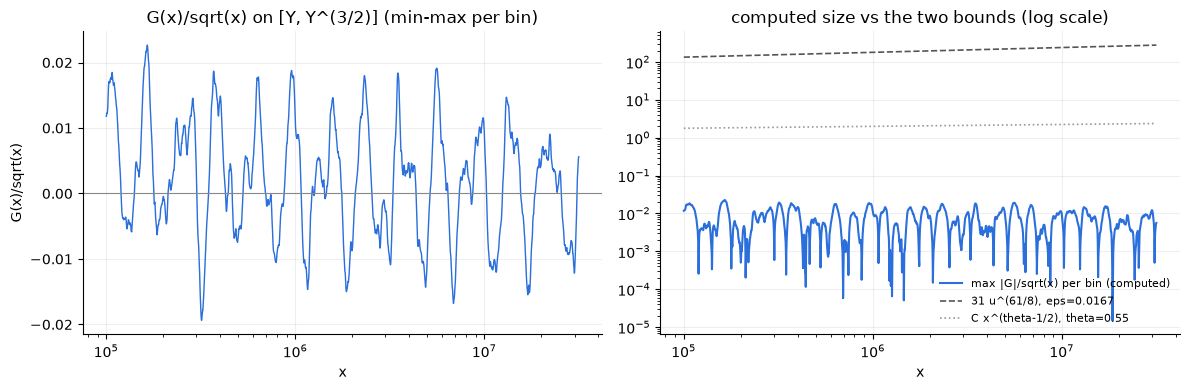

In [14]:
# Cell B: G at every integer of [Y, Y^(3/2)], float64 with an error bound, then the plot
import math, numpy as np
Y = int(Y_WINDOW); Z = int(round(Y ** 1.5))
w = G_window(Y, Z)
M, err = w["max"], w["err"]
# sup over all real x in [Y, Z]: chord bound 1/(8n) and sqrt(x) >= sqrt(n)
sup_real = max(M, 0) * (1 + 1 / Y) + err + 1 / (8 * Y ** 1.5)
xa = w["argmax"]
chk = G_arb(xa) / arb(xa).sqrt()
print("window [Y, Y^(3/2)] = [%d, %d]  (%d integers, %.1f s)" % (Y, Z, Z - Y + 1, w["seconds"]))
print("max over integers of G(n)/sqrt(n) = %.6f at n = %d   (Arb check at that n: %s)" % (M, xa, chk.str(8)))
print("min over integers of G(n)/sqrt(n) = %.6f" % np.min(w["bmin"]))
print("float error bound, in units of sqrt(n): %.1e" % err)
print("=> for every real x in the window, G(x)/sqrt(x) <= %.6f" % sup_real)
b31 = 31 * Y ** (61 * EPSILON / 8)
bth = C_THETA * Y ** (THETA - 0.5)
print("smallest value on the window of 31 u^(61/8): %.3f  -> bound holds here: %s" % (b31, sup_real <= b31))
print("smallest value on the window of C x^(theta-1/2): %.3f -> bound holds here: %s" % (bth, sup_real <= bth))
print("(observation on this window only; see the markdown above for why this certifies nothing global)")

import matplotlib.pyplot as plt
mid = np.sqrt(w["edges"][1:] * w["edges"][:-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].fill_between(mid, w["bmin"], w["bmax"], color="#2a6fdb", alpha=0.35, lw=0)
ax[0].plot(mid, w["bmax"], color="#2a6fdb", lw=1)
ax[0].axhline(0, color="#888", lw=0.8)
ax[0].set_xscale("log"); ax[0].set_xlabel("x"); ax[0].set_ylabel("G(x)/sqrt(x)")
ax[0].set_title("G(x)/sqrt(x) on [Y, Y^(3/2)] (min-max per bin)")
amax = np.maximum(np.abs(w["bmin"]), np.abs(w["bmax"]))
ax[1].plot(mid, amax, color="#2a6fdb", lw=1.5, label="max |G|/sqrt(x) per bin (computed)")
ax[1].plot(mid, 31 * mid ** (61 * EPSILON / 8), color="#555", lw=1.2, ls="--", label="31 u^(61/8), eps=%.4f" % EPSILON)
ax[1].plot(mid, C_THETA * mid ** (THETA - 0.5), color="#999", lw=1.2, ls=":", label="C x^(theta-1/2), theta=%.2f" % THETA)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("x")
ax[1].set_title("computed size vs the two bounds (log scale)")
ax[1].legend(frameon=False, fontsize=8)
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=0.2)
plt.tight_layout(); plt.show()

---
# Part 3. Putting the two together

**The chain of the paper, in five lines.**
1. $W_T\ge0$ on every window $(-T,T)$ $\iff$ the Riemann hypothesis (Theorem `thm:all-support`).
2. It is enough to bound the prime sum: $G(x)\le C_\theta x^\theta$ on arbitrarily large windows $[Y,Y^{3/2}]$, for every $\theta>\frac12$ (Proposition `prop:growing-window`).
3. That bound follows from an upper estimate for a finite mean difference at each $x$ (the mean bound; Propositions `prop:finite-to-window`, `prop:simultaneous-slope`), giving $G(x)\le31\sqrt x\,u^{61/8}$.
4. The mean estimate follows from a slope inequality for Hermitian lattices, given a column package with uniform constants at each $x$ of the window.
5. The existence of such families of column packages is the theorem on families, due to L. Alpoge, resting on his Lean formalisation (Theorem `thm:alpoge-families`).

**What this notebook checked by computation.**
* Part 1, **rigorously** (ball arithmetic), on the windows actually run: lower bounds
  $\lambda_{\rm A}(T)\ge\mu_{\rm A}$, $\lambda^{\rm W}_T\ge\mu_{\rm W}$ for those $T$ (and all smaller ones).
* Part 2, **numerically** (Arb at single points; float64 with an error bound on a window), on the windows run:
  $G(x)/\sqrt x$ is small there, far below $31u^{61/8}$ and $C x^{\theta-1/2}$.

**What only a proof can give.** The bound on **all** sufficiently large windows (steps 2–5), hence $W_T\ge0$ for
**every** $T$. No run of this notebook verifies global positivity, and none of its output claims it.

**Read the proofs.** `sign-radial-intersection-form-idele-class-group.pdf` (the paper) and
`column-packages-character-families.pdf` (the annex: the written account of the theorem on families), both in
the same folder as this notebook.

In [15]:
# Summary of this run (what was certified / observed — nothing global)
import flint, platform
print("python-flint", flint.__version__, "| Python", platform.python_version())
print()
print("Part 1 (rigorous, ball arithmetic):")
print("  T = (1/2) log 5 :", "paper's Theorem thm:log5W REPRODUCED" if all_ok else "NOT reproduced in this run")
try:
    if res.get("status") == "done":
        cs = res["cases"]
        pr = [cs[CASES[0][0]], cs[CASES[1][0]]]; wv = [cs[CASES[2][0]], cs[CASES[3][0]]]
        f = lambda v: min(v, key=float) if None not in v else None
        print("  %s : lambda_A >= %s, lambda^W >= %s   (None = no certificate by this method)" %
              (res["label"], f(pr), f(wv)))
    else:
        print("  %s : no certificate produced by this method (%s)" % (res["T"], res.get("status")))
except NameError:
    print("  (section 6 not run)")
print()
print("Part 2 (numerical illustration, primes only):")
try:
    print("  window [%d, %d]: sup G(x)/sqrt(x) <= %.5f ; 31 u^(61/8) >= %.1f there" % (Y, Z, sup_real, b31))
except NameError:
    print("  (Cell B not run)")
print()
print("Not verified by any computation here: W_T >= 0 for every T (that is the paper's theorem,")
print("given the theorem on families of L. Alpoge).")

python-flint 0.9.0 | Python 3.13.0

Part 1 (rigorous, ball arithmetic):
  T = (1/2) log 5 : paper's Theorem thm:log5W REPRODUCED
  T = 0.85 : lambda_A >= 1e-14, lambda^W >= 1e-20   (None = no certificate by this method)

Part 2 (numerical illustration, primes only):
  window [100000, 31622777]: sup G(x)/sqrt(x) <= 0.02272 ; 31 u^(61/8) >= 133.9 there

Not verified by any computation here: W_T >= 0 for every T (that is the paper's theorem,
given the theorem on families of L. Alpoge).
